# International students' mental health

![Illustration of silhouetted heads](mentalhealth.jpg)

Does studying in a foreign country affect mental health? A Japanese international university surveyed its students in 2018. The published study found that international students were at higher risk of mental health difficulties, and that social connectedness and acculturative stress both predicted depression.

This notebook checks those findings against the survey data (`students.csv`) using SQL, and looks at whether length of stay matters. The queries run on [DuckDB](https://duckdb.org/), which reads the CSV directly.

| Field | Description |
|---|---|
| `inter_dom` | International (`Inter`) or domestic (`Dom`) student |
| `japanese_cate`, `english_cate` | Japanese and English proficiency |
| `academic` | Undergraduate or graduate |
| `age` | Age |
| `stay` | Length of stay in years |
| `todep` | Depression score (PHQ-9, 0-27, higher is worse) |
| `tosc` | Social connectedness score (SCS, higher is more connected) |
| `toas` | Acculturative stress score (ASISS, higher is more stress) |

In [1]:
import duckdb
import matplotlib.pyplot as plt

con = duckdb.connect()
con.sql("CREATE TABLE students AS SELECT * FROM 'students.csv' WHERE inter_dom IS NOT NULL")


def query(sql):
    """Run a SQL query and return the result as a DataFrame."""
    return con.sql(sql).df()


query("SELECT * FROM students LIMIT 5")

,inter_dom,region,gender,academic,age,age_cate,stay,stay_cate,japanese,japanese_cate,...,friends_bi,parents_bi,relative_bi,professional_bi,phone_bi,doctor_bi,religion_bi,alone_bi,others_bi,internet_bi
0,Inter,SEA,Male,Grad,24,4,5,Long,3,Average,...,Yes,Yes,No,No,No,No,No,No,No,No
1,Inter,SEA,Male,Grad,28,5,1,Short,4,High,...,Yes,Yes,No,No,No,No,No,No,No,No
2,Inter,SEA,Male,Grad,25,4,6,Long,4,High,...,No,No,No,No,No,No,No,No,No,No
3,Inter,EA,Female,Grad,29,5,1,Short,2,Low,...,Yes,Yes,Yes,Yes,No,No,No,No,No,No
4,Inter,EA,Female,Grad,28,5,1,Short,1,Low,...,Yes,Yes,No,Yes,No,Yes,Yes,No,No,No


## 1. Who answered the survey?

In [2]:
query("""
SELECT inter_dom,
       COUNT(*) AS num_students,
       ROUND(AVG(age), 1) AS average_age,
       ROUND(AVG(stay), 1) AS average_stay
FROM students
GROUP BY inter_dom
ORDER BY num_students DESC
""")

,inter_dom,num_students,average_age,average_stay
0,Inter,201,21.0,2.1
1,Dom,67,20.4,2.4


## 2. International and domestic students compared

In [3]:
query("""
SELECT inter_dom,
       COUNT(*) AS num_students,
       ROUND(AVG(todep), 2) AS average_phq,
       ROUND(AVG(tosc), 2) AS average_scs,
       ROUND(AVG(toas), 2) AS average_as,
       ROUND(100.0 * AVG(CASE WHEN todep >= 10 THEN 1 ELSE 0 END), 1) AS pct_phq_10_plus
FROM students
GROUP BY inter_dom
ORDER BY inter_dom DESC
""")

,inter_dom,num_students,average_phq,average_scs,average_as,pct_phq_10_plus
0,Inter,201,8.04,37.42,75.56,34.3
1,Dom,67,8.61,37.64,62.84,40.3


A PHQ-9 score of 10 or more is the usual screening threshold for moderate depression.

## 3. Does length of stay matter?

International students only, grouped by years of stay.

In [4]:
by_stay = query("""
SELECT stay,
       COUNT(*) AS count_int,
       ROUND(AVG(todep), 2) AS average_phq,
       ROUND(AVG(tosc), 2) AS average_scs,
       ROUND(AVG(toas), 2) AS average_as
FROM students
WHERE inter_dom = 'Inter'
GROUP BY stay
ORDER BY stay DESC
""")
by_stay

,stay,count_int,average_phq,average_scs,average_as
0,10,1,13.00,32.00,50.00
1,8,1,10.00,44.00,65.00
2,7,1,4.00,48.00,45.00
3,6,3,6.00,38.00,58.67
4,5,1,0.00,34.00,91.00
5,4,14,8.57,33.93,87.71
6,3,46,9.09,37.13,78.00
7,2,39,8.28,37.08,77.67
8,1,95,7.48,38.11,72.80


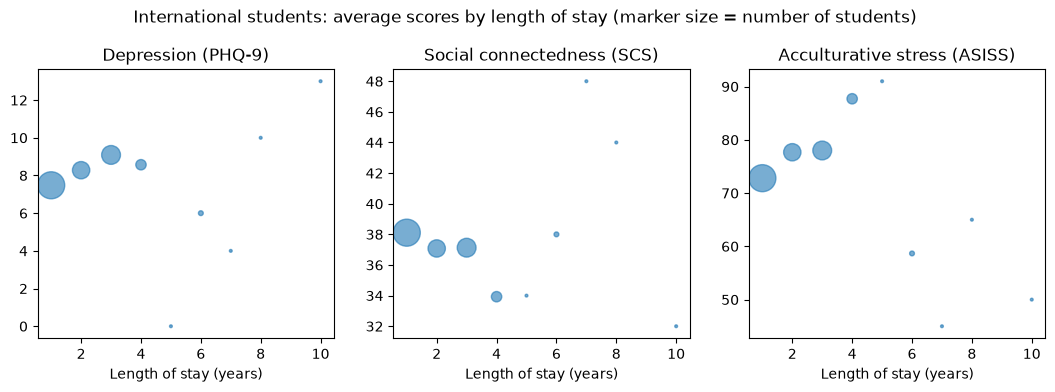

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
panels = [("average_phq", "Depression (PHQ-9)"),
          ("average_scs", "Social connectedness (SCS)"),
          ("average_as", "Acculturative stress (ASISS)")]
for ax, (col, title) in zip(axes, panels):
    ax.scatter(by_stay["stay"], by_stay[col], s=by_stay["count_int"] * 4, alpha=0.6)
    ax.set_xlabel("Length of stay (years)")
    ax.set_title(title)
fig.suptitle("International students: average scores by length of stay (marker size = number of students)", y=1.05)
plt.show()

Very few students have stayed more than four years, so those averages are based on one to three people each and should not be read as a trend.

## 4. Do connectedness and stress track depression?

Correlations among international students.

In [6]:
query("""
SELECT ROUND(CORR(todep, tosc), 2) AS depression_vs_connectedness,
       ROUND(CORR(todep, toas), 2) AS depression_vs_acculturative_stress,
       ROUND(CORR(todep, stay), 2) AS depression_vs_stay
FROM students
WHERE inter_dom = 'Inter'
""")

,depression_vs_connectedness,depression_vs_acculturative_stress,depression_vs_stay
0,-0.54,0.41,0.07


## Findings

- 201 international and 67 domestic students answered the survey.
- In this sample, international students do **not** report more depressive symptoms than domestic students: the average PHQ-9 score is 8.0 against 8.6, and 34% against 40% score 10 or more. What differs clearly is acculturative stress, which averages 75.6 for international students and 62.8 for domestic students.
- Among international students, depression scores are moderately related to both of the factors the study highlighted: lower social connectedness (r = -0.54) and higher acculturative stress (r = 0.41).
- Length of stay on its own is almost unrelated to depression (r = 0.07). Over the first four years, where there are enough students to compare, acculturative stress rises (72.8 in year one to 87.7 in year four) and social connectedness falls slightly (38.1 to 33.9), while the depression score moves between 7.5 and 9.1.

So the data supports the study's point about connectedness and stress, but not a simple "longer stay, worse mental health" story. The survey is a single snapshot of self-selected respondents, so none of this shows cause and effect.